# Pattern Formation: Gray-Scott and Swift-Hohenberg

Stripes, spots and labyrinths appear spontaneously in many systems: in chemical reactions, on animal
coats, in convecting fluids. Two classic models of pattern formation are the **Gray-Scott** system of
two reacting and diffusing chemicals,

$$
\frac{\partial u}{\partial t} = D_u \nabla^2 u - u v^2 + F\,(1 - u), \qquad
\frac{\partial v}{\partial t} = D_v \nabla^2 v + u v^2 - (F + k)\,v,
$$

and the **Swift-Hohenberg** equation, a model for convection rolls,

$$
\frac{\partial u}{\partial t} = r\,u - (1 + \nabla^2)^2 u + g\,u^2 - u^3 .
$$

Both consist of a linear part with spatial derivatives and a local nonlinear part. On a periodic domain
the linear part is diagonal in Fourier space, where it can be integrated *exactly*. This is what the
exponential time differencing schemes of *numgrids* do: `evolve(..., linear=L, method="ETDRK4", dt=...)`
steps the Fourier coefficients forward and evaluates the nonlinear terms on the grid, with fast Fourier
transforms in between. The time step is then limited by the reaction terms only.

In this notebook we

1. grow a labyrinth from a few seeds with the Gray-Scott system and check the time step,
2. change two parameters and get spots that divide like cells,
3. let stripes and hexagons emerge from noise with the Swift-Hohenberg equation, and compare with what
   theory says about them.

## The Gray-Scott System

The chemical $u$ is fed at the rate $F$ and consumed by the autocatalytic reaction $u + 2v \to 3v$; the
chemical $v$ is removed at the rate $F + k$. The state $u = 1$, $v = 0$ is stable, but a local
disturbance can ignite the reaction and spread.

The linear part of a system is a nested list of operators, one row per equation. Here it contains the two
diffusion terms. The right-hand side function returns the reaction terms.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from numgrids import *

size = 2.0
grid = Grid(x=periodic(128, 0, size), y=periodic(128, 0, size))
X, Y = grid.meshed_coords

Du, Dv = 2e-5, 1e-5
Lap = grid.laplacian_operator()
diffusion = [[Du * Lap, None],
             [None, Dv * Lap]]


def reaction(F, k):
    def rhs(t, u, v):
        uvv = u * v**2
        return -uvv + F * (1 - u), uvv - (F + k) * v
    return rhs

print(grid)

Grid(shape=(128, 128), ndims=2, axes=[
    EquidistantAxis(num_points=128, low=0, high=2.0, periodic=True, name='x'),
    EquidistantAxis(num_points=128, low=0, high=2.0, periodic=True, name='y')
])


The initial state is $u = 1$, $v = 0$ with a dozen seeds at random positions. The random number generator
has a fixed seed, so the notebook always produces the same patterns.

In [2]:
rng = np.random.default_rng(1)

seeds = np.zeros(grid.shape)
for cx, cy in rng.uniform(0.2 * size, 0.8 * size, (12, 2)):
    seeds += np.exp(-((X - cx)**2 + (Y - cy)**2) / (2 * 0.04**2))
seeds = np.minimum(seeds, 1)

u0 = 1 - 0.5 * seeds
v0 = 0.25 * seeds

### A labyrinth

For $F = 0.037$, $k = 0.06$ every seed grows into a ring, the rings break up into stripes, and the stripes
fill the domain with a labyrinth. We integrate up to $t = 4000$ with the fourth-order scheme `ETDRK4` and
keep six snapshots.

In [3]:
times = np.linspace(0, 4000, 6)

start = time.perf_counter()
labyrinth = evolve(grid, reaction(F=0.037, k=0.06), (u0, v0), t_span=(0, 4000), t_eval=times,
                   linear=diffusion, method="ETDRK4", dt=2.0)
elapsed = time.perf_counter() - start

u, v = labyrinth.u                       # each of shape (6, 128, 128)
print(labyrinth.message)
print(f"{elapsed:.1f} s for {grid.size} grid points and two fields\n")
print("     t    min(u)   max(v)   area with v > 0.15")
for t, ui, vi in zip(times, u, v):
    print(f"{t:6.0f}    {ui.min():.3f}    {vi.max():.3f}    {np.mean(vi > 0.15):6.1%}")

The integration reached the end of the time interval with 2000 steps of ETDRK4.
5.3 s for 16384 grid points and two fields

     t    min(u)   max(v)   area with v > 0.15
     0    0.500    0.250      1.7%
   800    0.264    0.388     18.3%
  1600    0.270    0.382     29.4%
  2400    0.270    0.382     44.0%
  3200    0.259    0.396     51.7%
  4000    0.264    0.379     54.6%


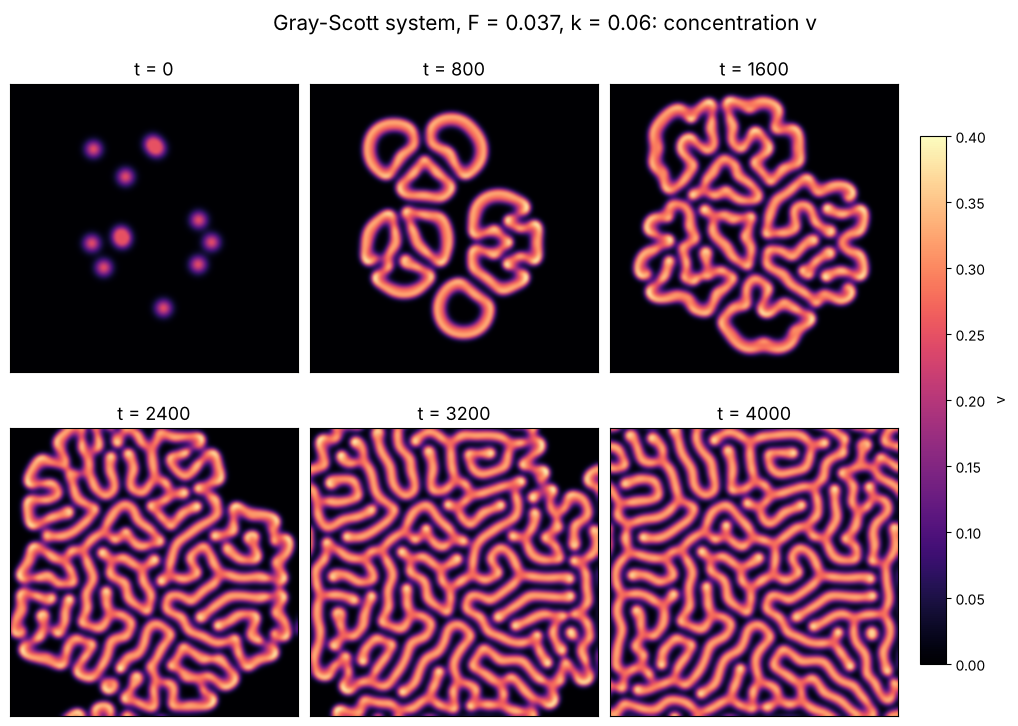

In [4]:
def show(ax, field, title, **kwargs):
    kwargs = {"cmap": "magma", "vmin": 0, "vmax": 0.4, "interpolation": "bicubic", **kwargs}
    im = ax.imshow(field.T, origin="lower", extent=(0, size, 0, size), **kwargs)
    ax.set_title(title, fontsize=13)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for ax, t, vi in zip(axes.flat, times, v):
    im = show(ax, vi, f"t = {t:.0f}")
fig.suptitle("Gray-Scott system, F = 0.037, k = 0.06: concentration v", fontsize=15)
fig.tight_layout()
fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02, label="v")
plt.show()

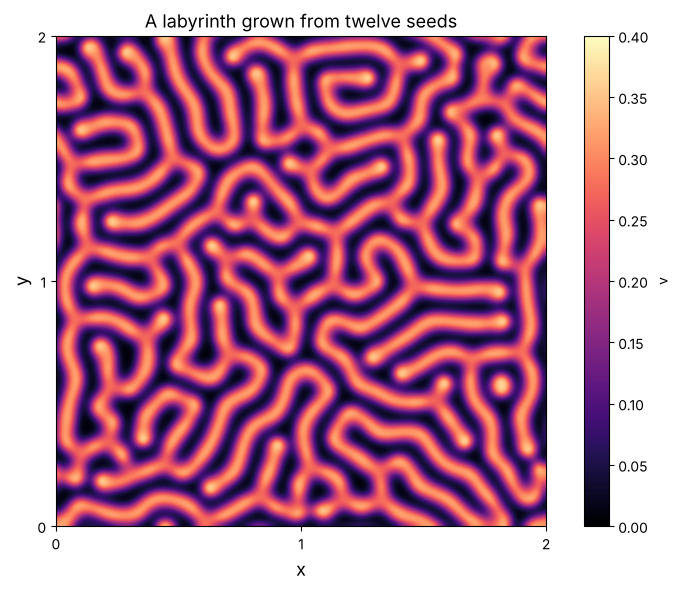

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
im = show(ax, v[-1], "A labyrinth grown from twelve seeds")
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel("y", fontsize=13)
ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2])
fig.colorbar(im, ax=ax, label="v")
fig.tight_layout()
plt.show()

### Is the time step small enough?

The fixed-step schemes have no error control, so we check the step ourselves: repeat the first part of the
run with half the step and compare. The error of a fourth-order scheme drops by a factor of 16; the
difference of the two runs therefore estimates the error of the coarser one. For comparison we also
run the second-order schemes `ETDRK2` and `IMEX2` with the same step.

In [6]:
reference = evolve(grid, reaction(F=0.037, k=0.06), (u0, v0), t_span=(0, 800),
                   linear=diffusion, method="ETDRK4", dt=1.0).final[1]

print("method     dt    largest difference in v at t = 800")
print(f"ETDRK4    2.0    {np.abs(v[1] - reference).max():.1e}")
for method in ("ETDRK2", "IMEX2"):
    res = evolve(grid, reaction(F=0.037, k=0.06), (u0, v0), t_span=(0, 800),
                 linear=diffusion, method=method, dt=2.0)
    print(f"{method:6s}    2.0    {np.abs(res.final[1] - reference).max():.1e}")

method     dt    largest difference in v at t = 800
ETDRK4    2.0    1.6e-05


ETDRK2    2.0    1.0e-02


IMEX2     2.0    3.8e-03


With $\Delta t = 2$ the snapshots of `ETDRK4` are accurate to about five digits. A step of this size is
possible because diffusion is integrated exactly; the reaction terms change on a time scale of
$1/(F + k) \approx 10$.

### Dividing spots

A small change of the parameters gives a different pattern. For $F = 0.03$, $k = 0.062$ the stripes are
unstable: every seed turns into spots, and the spots divide like cells until they fill the domain.

The integration reached the end of the time interval with 2000 steps of ETDRK4.  (5.2 s)


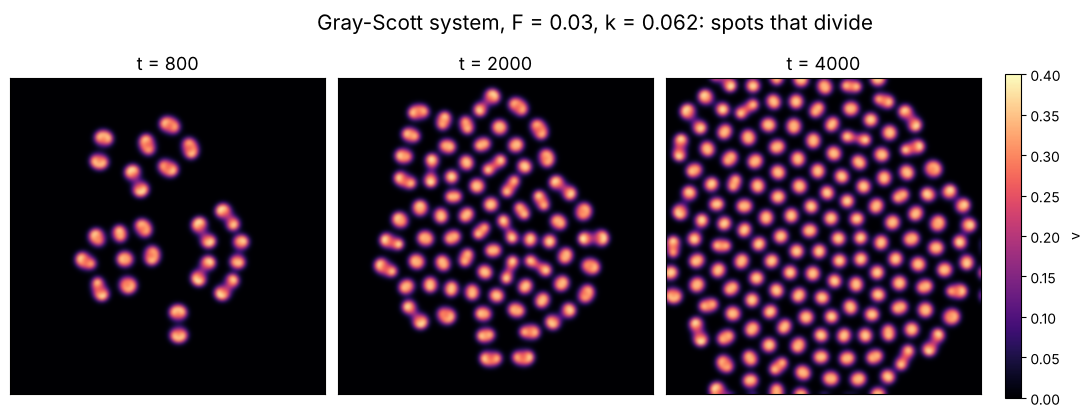

In [7]:
start = time.perf_counter()
spots = evolve(grid, reaction(F=0.03, k=0.062), (u0, v0), t_span=(0, 4000), t_eval=[800, 2000, 4000],
               linear=diffusion, method="ETDRK4", dt=2.0)
print(f"{spots.message}  ({time.perf_counter() - start:.1f} s)")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, t, vi in zip(axes, spots.t, spots.u[1]):
    im = show(ax, vi, f"t = {t:.0f}")
fig.suptitle("Gray-Scott system, F = 0.03, k = 0.062: spots that divide", fontsize=15)
fig.tight_layout()
fig.colorbar(im, ax=axes, shrink=0.9, pad=0.02, label="v")
plt.show()

## The Swift-Hohenberg Equation

The linear part $r - (1 + \nabla^2)^2$ of the Swift-Hohenberg equation amplifies Fourier modes
$e^{i \mathbf{k} \cdot \mathbf{x}}$ with the rate

$$
\sigma(\mathbf{k}) = r - (1 - |\mathbf{k}|^2)^2 ,
$$

so for $r > 0$ a band of modes around $|\mathbf{k}| = 1$ grows, and the nonlinear terms decide which
pattern they form.

The operator contains the mixed derivative $\partial_x^2 \partial_y^2$. Its matrix is dense: it would have
$128^4 \approx 2.7 \cdot 10^8$ entries here. On periodic grids there is a way around the matrix: the linear
part can be given as its **Fourier symbol**, the function $\sigma$ of the wave numbers.

The fourth derivative makes this problem stiff. The fastest decaying mode has the rate $-960$, which
limits explicit methods to steps of about $0.003$. We use $\Delta t = 0.5$.

In [8]:
size = 32 * np.pi                        # 16 wavelengths of the critical mode
grid = Grid(x=periodic(128, 0, size), y=periodic(128, 0, size))

rng = np.random.default_rng(2)
noise = 0.01 * rng.standard_normal(grid.shape)


def swift_hohenberg(r, g, t_end, t_eval=None):
    return evolve(grid, lambda t, u: g * u**2 - u * u**2, noise, t_span=(0, t_end), t_eval=t_eval,
                  linear=lambda kx, ky: r - (1 - kx**2 - ky**2)**2, method="ETDRK4", dt=0.5)


start = time.perf_counter()
stripes = swift_hohenberg(r=0.3, g=0.0, t_end=300, t_eval=[0, 5, 300])
hexagons = swift_hohenberg(r=0.1, g=1.0, t_end=500)
print(stripes.message)
print(hexagons.message)
print(f"{time.perf_counter() - start:.1f} s")

The integration reached the end of the time interval with 600 steps of ETDRK4.
The integration reached the end of the time interval with 1000 steps of ETDRK4.
2.3 s


Without the quadratic term ($g = 0$) the equation is symmetric under $u \to -u$ and forms **stripes**.
The quadratic term breaks this symmetry and favors **hexagons**.

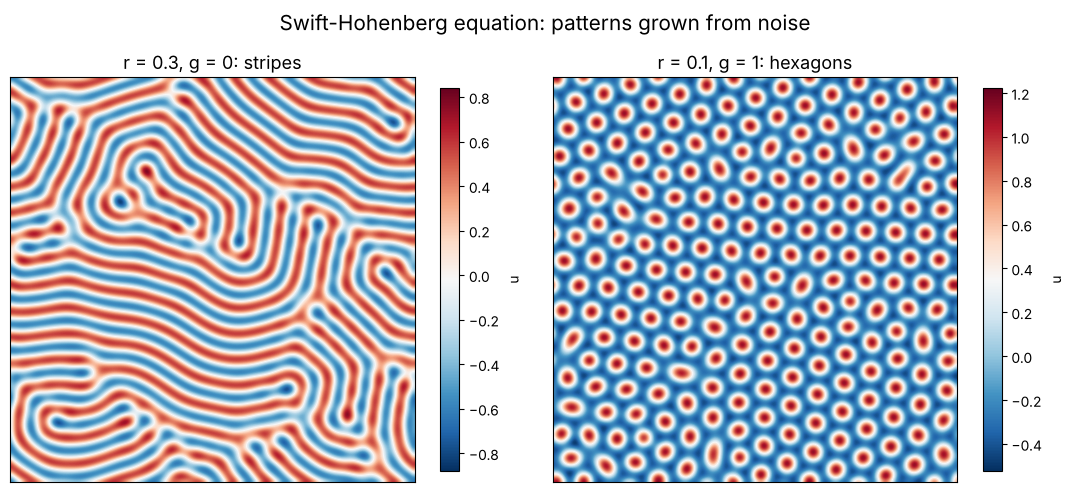

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, res, title in [(axes[0], stripes, "r = 0.3, g = 0: stripes"),
                       (axes[1], hexagons, "r = 0.1, g = 1: hexagons")]:
    im = show(ax, res.final, title, cmap="RdBu_r", vmin=None, vmax=None)
    fig.colorbar(im, ax=ax, shrink=0.85, label="u")
fig.suptitle("Swift-Hohenberg equation: patterns grown from noise", fontsize=15)
fig.tight_layout()
plt.show()

### Comparison with theory

Two exact statements can be checked.

**Linear growth.** As long as $u$ is small, the nonlinear terms are negligible, and every Fourier mode of
the noise grows exactly with its rate $\sigma(\mathbf{k})$. The scheme integrates the linear part without
error, so the numerical solution must follow this law. We compare the Fourier coefficients at $t = 5$
with the prediction.

**Wave number.** The fastest growing modes have $|\mathbf{k}| = 1$, so the stripes should have the wave
length $2\pi$.

In [10]:
k = 2 * np.pi * np.fft.fftfreq(128, d=size / 128)
KX, KY = np.meshgrid(k, k, indexing="ij")
sigma = 0.3 - (1 - KX**2 - KY**2)**2

predicted = np.exp(5 * sigma) * np.fft.fft2(noise)
computed = np.fft.fft2(stripes.u[1])
print(f"growth of the noise up to t = 5: largest deviation from exp(sigma t) = "
      f"{np.abs(computed - predicted).max() / np.abs(predicted).max():.1e}")

power = np.abs(np.fft.fft2(stripes.final))**2
print(f"mean wave number of the stripes: {np.sum(np.hypot(KX, KY) * power) / np.sum(power):.3f}")

growth of the noise up to t = 5: largest deviation from exp(sigma t) = 3.5e-04
mean wave number of the stripes: 0.993


The first number is not zero because the cubic term already acts on the growing noise: it is of the order
$u^2 \approx 10^{-4}$.

**Energy.** The Swift-Hohenberg equation is a gradient flow: it only ever decreases the functional

$$
\mathcal{F}[u] = \int \Big( \frac12 \big[(1 + \nabla^2) u\big]^2 - \frac{r}{2} u^2 - \frac{g}{3} u^3 + \frac14 u^4 \Big)\, dx\, dy .
$$

`grid.laplacian` and `grid.integrate` evaluate it for the snapshots of a run:

In [11]:
def energy(u, r, g):
    return grid.integrate(0.5 * (u + grid.laplacian(u))**2 - r / 2 * u**2 - g / 3 * u**3 + u**4 / 4)


times = [0, 20, 40, 60, 100, 200, 500]
run = swift_hohenberg(r=0.1, g=1.0, t_end=500, t_eval=times)
values = [energy(u, 0.1, 1.0) for u in run.u]

print("    t      energy")
for t, value in zip(times, values):
    print(f"{t:5.0f}   {value:10.4f}")
print("decreasing:", bool(np.all(np.diff(values) < 0)))

    t      energy
    0      71.5914
   20      -0.0309
   40      -1.9578
   60    -113.6092
  100    -132.1342
  200    -136.6064
  500    -138.9254
decreasing: True


## Summary

* `evolve(grid, N, u0, t_span, linear=L, method="ETDRK4", dt=...)` integrates stiff semilinear problems
  with a fixed step: the linear part exactly, the nonlinear part with a fourth-order Runge-Kutta scheme.
* For systems, `linear` is a nested list of operators and the nonlinear part returns one array per field.
* On periodic grids, linear parts with constant coefficients are handled in Fourier space. Two fields on
  a $128 \times 128$ grid take a few milliseconds per step.
* Operators with dense matrices, like $(1 + \nabla^2)^2$ in two dimensions, can be passed as Fourier
  symbols: `linear=lambda kx, ky: r - (1 - kx**2 - ky**2)**2`.
* There is no error control. Check the time step by comparing with a run with half the step.